# 3 · Choosing a graph builder

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/03_choosing_a_graph_builder.ipynb)

The TextGCN graph of tutorial 2 connects two words whenever they co-occur
more often than chance. That gives **millions of edges**: most of the memory
and most of the build time.

The **Related Word Filter (RWF)** of Pereira & de Castro (DCAI 2022) asks a
simple question: *what if only related words were connected?* The semantic
variant trains Word2Vec on the corpus. It keeps a word–word edge only when the
two embeddings are very similar, and keeps the TF-IDF document–word edges
unchanged.

Here we build three graphs **on the same preprocessed corpus**, train the same
GCN on each and compare them.

> **Runtime:** about 25 min on CPU. Building the TF-IDF + PMI graph takes about
> 4 min on any hardware, because it runs on the CPU; a GPU speeds up only the training.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | Your first classifier | How do I go from raw text to test accuracy? |
| 3 | **Choosing a graph builder** | How should words be connected? |
| 4 | Refining the graph | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

In [2]:
import pickle
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from text4gcn import GNN, Builder, TextPipeline
from text4gcn.builder import Frequency, Semantic
from text4gcn.datasets import twenty_newsgroups

In [3]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

Same data and preprocessing as tutorial 2: the graph is the only thing that changes.

In [4]:
shutil.rmtree(DATA_DIR, ignore_errors=True)   # start clean: outputs of older runs would be reused
twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)
TextPipeline(dataset_name=NAME, dataset_path=DATA_DIR, seed=SEED).execute(validation_ratio=0.10)

[2026/10/16 18:35:43] [INFO] ======================================== NLTK Configuration ========================================


[nltk_data] Downloading package stopwords to /home/vitor/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/vitor/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/vitor/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


[2026/10/16 18:35:43] [INFO] Random seed (shuffle) = <1234>
[2026/10/16 18:35:43] [INFO] Validation ratio = <0.1>
[2026/10/16 18:35:43] [INFO] 
[2026/10/16 18:35:43] [INFO] ============================= CLEANED DATA: Removed rare & stop-words. =============================
[2026/10/16 18:35:43] [INFO] Start process: 1792172143.3868046


[2026/10/16 18:35:44] [INFO] Rare-Count = <5>
[2026/10/16 18:35:44] [INFO] Elapsed time is 1.017390 seconds.
[2026/10/16 18:35:44] [INFO] 
[2026/10/16 18:35:44] [INFO] ============================ SHUFFLED DATA: Corpus documents shuffled. =============================
[2026/10/16 18:35:44] [INFO] Start process: 1792172144.4045818
[2026/10/16 18:35:44] [INFO] Elapsed time is 0.154298 seconds.
[2026/10/16 18:35:44] [INFO] 
[2026/10/16 18:35:44] [INFO] ======================= PREPARED WORDS: Vocabulary & word-vectors extracted. =======================
[2026/10/16 18:35:44] [INFO] Start process: 1792172144.5590243


[2026/10/16 18:35:50] [INFO] Elapsed time is 5.530060 seconds.
[2026/10/16 18:35:50] [INFO] 
[2026/10/16 18:35:50] [INFO] ======================== EXTRACTED NODE FEATURES: x, y, tx, ty, allx, ally. ========================
[2026/10/16 18:35:50] [INFO] Start process: 1792172150.0894458


/home/vitor/repos/Text4GNNs/text4gcn/text4gcn/modules/node_features.py:76: RuntimeWarning: invalid value encountered in divide
  mean_doc_vec = (doc_vec / len(words)).tolist()


[2026/10/16 18:35:51] [INFO] x.shape=(1973, 300), y.shape=(1973, 4)
[2026/10/16 18:35:51] [INFO] tx.shape=(1455, 300), ty.shape=(1455, 4)
[2026/10/16 18:35:51] [INFO] allx.shape=(13082, 300), ally.shape=(13082, 4)
[2026/10/16 18:35:51] [INFO] Elapsed time is 1.710797 seconds.
[2026/10/16 18:35:51] [INFO] 


## Three ways to connect words

| Graph | Word–word edges | `Builder` |
|---|---|---|
| **TF-IDF + PMI** (TextGCN) | positive PMI over a sliding window | `Builder.Tfidf` |
| **Word2Vec RWF** (DCAI 2022) | adjacent words whose corpus-trained Word2Vec embeddings have cosine similarity ≥ `threshold`, and positive PMI | `Builder.Word2Vec` |
| **Cosine similarity** | words whose WordNet definitions are similar: cosine of the TF-IDF vectors of their glosses > `threshold` | `Builder.CosineSimilarity` |

All three keep the same TF-IDF document–word edges, so the graphs differ only in
their word–word edges. Each builder writes its
own adjacency file, and `GNN(builder=...)` selects which one to train on.

In [5]:
graphs = {
    "TF-IDF + PMI": (Builder.Tfidf,
                     lambda: Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)),
    "Word2Vec RWF": (Builder.Word2Vec,
                     lambda: Semantic(dataset_name=NAME, dataset_path=DATA_DIR).word2vec(
                         training_algorithm=1,      # 1 = skip-gram, 0 = CBOW
                         embedding_dimension=300, num_epochs=20, threshold=0.7)),
    "Cosine similarity": (Builder.CosineSimilarity,
                          lambda: Semantic(dataset_name=NAME, dataset_path=DATA_DIR).cosine_similarity(
                              threshold=0.95)),
}

In [6]:
vocab_size = len((DATA_DIR / f"{NAME}.shuffled" / f"{NAME}.vocab").read_text(encoding="utf-8").split())
train_size = len((DATA_DIR / f"{NAME}.shuffled" / f"{NAME}.train").read_text(encoding="utf-8").split())
words = slice(train_size, train_size + vocab_size)   # word nodes sit between train and test documents


def word_word_edges(stats):
    with open(stats.path, "rb") as f:
        return pickle.load(f).tocsr()[words, words].nnz


rows = []
for name, (builder, build) in graphs.items():
    start = time.perf_counter()
    stats = build()
    build_seconds = time.perf_counter() - start

    result = GNN(dataset_name=NAME, dataset_path=DATA_DIR, log_dir=LOG_DIR / builder.value,
                 builder=builder, seed=SEED).fit()
    rows.append({
        "graph": name,
        "edges": stats.n_edges,
        "word–word": word_word_edges(stats),
        "file (MiB)": stats.file_bytes / 2**20,
        "build (s)": build_seconds,
        "test accuracy": result.test_accuracy,
        "epochs": result.epochs_trained,
    })

comparison = pd.DataFrame(rows).set_index("graph")
comparison.style.format({"edges": "{:,}", "word–word": "{:,}", "file (MiB)": "{:.1f}", "build (s)": "{:.0f}",
                         "test accuracy": "{:.2%}"})

[2026/10/16 18:35:51] [INFO] =============== EXTRACTED ADJACENCY MATRIX: Heterogenous doc-word adjacency matrix. ================
[2026/10/16 18:35:51] [INFO] Start process: 1792172151.8229642


[2026/10/16 18:35:52] [INFO] Calculating PMI


[2026/10/16 18:39:37] [INFO] Calculating TF-IDF


[2026/10/16 18:39:39] [INFO] [INFO] (4534779, (4534779, 4534779)), shape=(14537, 14537)


[2026/10/16 18:39:41] [INFO] GraphBuildStats(frequency.tfidf: nodes=14537, edges(nnz)=4534779, density=2.145886e-02, file=51.95 MiB)
[2026/10/16 18:39:41] [INFO] Elapsed time is 229.919453 seconds.
[2026/10/16 18:39:41] [INFO] 
[2026/10/16 18:39:41] [WARN] Directory:'data/log' already exists, not overwritten.


...

Epoch:0048, train_loss=1.20378, train_acc=0.99797, val_loss=1.36915, val_acc=0.92694, time=7.86413


Epoch:0049, train_loss=1.20346, train_acc=0.99797, val_loss=1.36916, val_acc=0.92694, time=7.81794
Early stopping at epoch 49. Restoring best validation checkpoint (val_loss=1.36914).

Completed 49 epochs — train_loss=1.2035, best_val_loss=1.3691, last_train_acc=0.9980



Optimization Finished!



Test set results: loss=1.28940, accuracy=0.85498, time=0.63604

Test Precision, Recall and F1-Score...
              precision    recall  f1-score   support

           0     0.7770    0.8802    0.8254       384
           1     0.9239    0.8654    0.8937       379
           2     0.7943    0.7249    0.7580       309
           3     0.9243    0.9243    0.9243       383

    accuracy                         0.8550      1455
   macro avg     0.8549    0.8487    0.8504      1455
weighted avg     0.8577    0.8550    0.8549      1455


Macro average Test Precision, Recall and F1-Score...
(0.854890845423415, 0.8487111919297993, 0.8503622512001445, None)

Micro average Test Precision, Recall and F1-Score...
(0.8549828178694158, 0.8549828178694158, 0.8549828178694158, None)

Weighted average Test Precision, Recall and F1-Score...
(0.8577277458357838, 0.8549828178694158, 0.8549214289558619, None)

Confusion Matrix...
[[338   7  33   6]
 [ 25 328  12  14]
 [ 66  10 224   9]
 [  6  10  13 354]

,edges,word–word,file (MiB),build (s),test accuracy,epochs
graph,,,,,,
TF-IDF + PMI,"4,534,779","4,258,440",52.0,230,86.74%,52
Word2Vec RWF,"279,559","3,220",3.3,114,85.50%,50
Cosine similarity,"293,679","17,340",3.4,6,85.50%,49


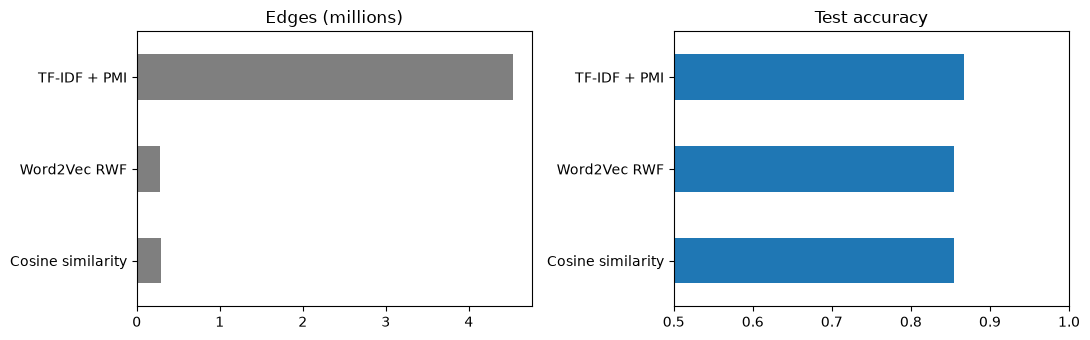

In [7]:
fig, (ax_edges, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.5))
(comparison["edges"] / 1e6).plot.barh(ax=ax_edges, color="tab:gray", title="Edges (millions)")
comparison["test accuracy"].plot.barh(ax=ax_acc, color="tab:blue", title="Test accuracy", xlim=(0.5, 1))
for ax in (ax_edges, ax_acc):
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()

## Reading the results

On our CPU run (seed 1234):

* The **Word2Vec RWF graph had 16× fewer edges** (0.28 M vs 4.5 M), a 3 MiB file
  instead of 52 MiB, and was built in about 2 min instead of 4. It lost about one
  point of accuracy (85.5% vs 86.7%). This is the trade-off reported in the
  DCAI 2022 paper: **much smaller graphs with comparable accuracy**.
* The **word–word** column shows where the difference lies (each word–word edge is
  stored in both directions). The PMI of TextGCN adds 4.3 M word–word entries. The
  RWF keeps 3,220 and the cosine graph 17,340: both graphs are almost entirely
  made of the TF-IDF document–word edges.
* The RWF and cosine graphs reach **exactly the same accuracy**. In separate runs
  (not shown), a graph with the same document–word edges and *no* word–word edge
  at all also reached 85.5%, and so did RWF thresholds from 0.95 (79 word–word
  edges) to 0.5 (11,127). Their weights explain part of it: an RWF edge weighs its
  pair count divided by the largest pair count, mostly around 0.001, while a TF-IDF
  edge weighs about 4.

On this corpus the **document–word edges carry the signal**. The 4.3 M PMI edges
buy about one point of accuracy; the RWF and cosine word–word edges change graph
size, not accuracy.

Which one to choose:

* **Start with TF-IDF + PMI.** It is the TextGCN baseline and the most accurate here.
* **Use Word2Vec RWF** when memory or build time matters: about one point less for a
  16× smaller graph.
* **`threshold`** changes the size of the RWF graph more than its accuracy. Measure
  on your own data before tuning it.
* The cosine graph compares WordNet definitions, so it is meaningful for English only.
* The syntactic graphs (`Syntactic.dependency_parsing()`, `Syntactic.linguistic_inquiry()`)
  follow the same pattern but need Stanford CoreNLP or a LIWC dictionary. See the
  [builders guide](https://vitormeriat.github.io/text4gcn/guides/builders/).

**Next:** the builder decides which edges exist. [4 · Refining the graph](https://vitormeriat.github.io/text4gcn/tutorials/04_refining_the_graph/)
prunes an existing graph instead, without rebuilding it.